# Cell surface staining and cell-cell fusion assays

In [1]:
# Imports
import os
import warnings
import seaborn as sns
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt, ticker as mticker

from scipy.interpolate import splrep, splev

# Plotting colors
tol_muted_adjusted = [
    "#000000",
    "#CC6677", 
    "#1f78b4", 
    "#DDCC77", 
    "#117733", 
    "#882255", 
    "#88CCEE",
    "#44AA99", 
    "#999933", 
    "#AA4499", 
    "#EE7733",
    "#CC3311",
    "#DDDDDD",
]

# Seaborn style settings
sns.set(rc={
    "figure.dpi":300, 
    "savefig.dpi":300,
    "svg.fonttype":"none",
})
sns.set_style("ticks")
sns.set_palette(tol_muted_adjusted)

# Suppress warnings
warnings.simplefilter("ignore")

In [2]:
# Figure directory
out_dir = "Figures/"

In [3]:
# ---- Settings ----
FUSION_CSV_PATH = "Data/pH_mutants_fusion.csv"      # <-- change to your fusion CSV path
STAINING_CSV_PATH = "Data/pH_mutants_staining.csv"  # <-- change to your staining CSV path

def plot_data(FUSION_CSV_PATH, STAINING_CSV_PATH, out_dir, fig_name):
 
    # ---- Load data ----
    fusion_df = pd.read_csv(FUSION_CSV_PATH)
    staining_df = pd.read_csv(STAINING_CSV_PATH)
     
    # Make sure pH is treated as a categorical variable so bars are evenly spaced
    # and ordered numerically (descending, matching example: 7.5 -> 4.5)
    ph_order = sorted(fusion_df["pH"].unique(), reverse=True)
    fusion_df["pH"] = pd.Categorical(fusion_df["pH"], categories=ph_order, ordered=True)
     
    # Order of antibodies (as they first appear in the staining CSV)
    antibody_order = staining_df["antibody"].unique().tolist()
     
    # Mutants: use the fusion CSV's order, but make sure every mutant present in
    # either file gets a column (in case one file has extras)
    mutant_order = list(fusion_df["mutant"].unique())
    for m in staining_df["mutant"].unique():
        if m not in mutant_order:
            mutant_order.append(m)
     
    plt.rcParams.update({
        "font.size": 6,
        "axes.titlesize": 6,
        "axes.labelsize": 6,
        "xtick.labelsize": 6,
        "ytick.labelsize": 6,
        "legend.fontsize": 6,
        "legend.title_fontsize": 6,
    })
     
    # A distinct color per antibody
    antibody_palette = dict(zip(antibody_order, sns.color_palette("Set2", len(antibody_order))))
     
    # ---- Set up a 2-row grid: staining (top) / fusion (bottom), one column per mutant ----
    n_mutants = len(mutant_order)
    fig, axes = plt.subplots(
        2, n_mutants, figsize=(0.625 * n_mutants, 3), sharey="row"
    )
     
    # Ensure axes is always 2D-indexable even with a single mutant
    if n_mutants == 1:
        axes = axes.reshape(2, 1)
     
    for col, mutant in enumerate(mutant_order):
        ax_top = axes[0, col]
        ax_bottom = axes[1, col]
     
        # ---- Top row: staining vs antibody ----
        sub_stain = staining_df[staining_df["mutant"] == mutant]
     
        # sns.barplot(
        #     data=sub_stain,
        #     x="antibody",
        #     y="staining",
        #     order=antibody_order,
        #     hue="antibody",
        #     hue_order=antibody_order,
        #     palette=antibody_palette,
        #     edgecolor="black",
        #     errorbar="sd",
        #     # capsize=0.15,
        #     legend=False,
        #     ax=ax_top,
        # )
     
        sns.stripplot(
            data=sub_stain,
            x="antibody",
            y="staining",
            order=antibody_order,
            palette=antibody_palette, # color="black",
            jitter=True,
            size=4,
            edgecolor="black",
            linewidth=0.5,
            alpha=0.7,
            ax=ax_top,
            legend=False,
        )
     
        ax_top.set_title(mutant, fontsize=8)
        ax_top.set_xlabel("antibody", fontsize=6)
        ax_top.set_ylabel("cell surface expression\nfold change compared\nto unmutated GPC" if col == 0 else "", fontsize=8)
        ax_top.set_yscale("log", base=2)
        ax_top.yaxis.set_minor_locator(mticker.NullLocator())  # no minor ticks
        ax_top.set_ylim(0.1, 10.5)
        yticks = [0.125, 0.25, 0.5, 1, 2, 4, 8]
        ax_top.set_yticks(yticks)
        ax_top.set_yticklabels(labels=[str(x) for x in yticks], fontsize=6)
        ax_top.tick_params(axis="x", rotation=90, length=4, width=1)
        ax_top.tick_params(axis="y", length=4, width=1)
        # Change all spines
        for axis in ["top", "bottom", "left", "right"]:
            ax_top.spines[axis].set_linewidth(1)

        if col != 0:
            ax_top.spines["left"].set_visible(False)
            ax_top.spines["left"].set_linewidth(0)
            ax_top.tick_params(axis="y", left=False, labelleft=False)

        # Add line at 1
        ax_top.axhline(y=1, color="black", linestyle="--", linewidth=1, alpha=0.75)
     
        # ---- Bottom row: fusion vs pH ----
        sub_fusion = fusion_df[fusion_df["mutant"] == mutant]
     
        sns.barplot(
            data=sub_fusion,
            x="pH",
            y="fusion",
            order=ph_order,
            color="lightgray",
            edgecolor="black",
            errorbar="se",
            capsize=0.15,
            errwidth=1,
            ax=ax_bottom,
            legend=False,
        )
     
        sns.stripplot(
            data=sub_fusion,
            x="pH",
            y="fusion",
            order=ph_order,
            color="black",
            dodge=False,       # set True if you want replicates offset side-by-side
            jitter=True,
            size=4,
            edgecolor="black",
            linewidth=0.5,
            alpha=0.7,
            ax=ax_bottom,
            legend=False,
        )
     
        ax_bottom.set_xlabel("pH", fontsize=6)
        ax_bottom.set_ylabel("cell-cell fusion\n(GFP-positive/cell area)" if col == 0 else "",  fontsize=8)
        yticks = [0, 0.25, 0.5, 0.75]
        ax_bottom.set_yticks(yticks)
        ax_bottom.set_yticklabels(labels=[str(x) for x in yticks], fontsize=6)
        ax_bottom.tick_params(axis="x", rotation=90, length=4, width=1)
        ax_bottom.tick_params(axis="y", length=4, width=1)
        # Change all spines
        for axis in ["top", "bottom", "left", "right"]:
            ax_bottom.spines[axis].set_linewidth(1)

        if col != 0:
            ax_bottom.spines["left"].set_visible(False)
            ax_bottom.spines["left"].set_linewidth(0)
            ax_bottom.tick_params(axis="y", left=False, labelleft=False)
     
    plt.tight_layout()
    plt.subplots_adjust(wspace=0.1)
    sns.despine()
    
    # Make output dir if doesn't exist
    if not os.path.exists(out_dir):
        os.mkdir(out_dir)
    
    plt.savefig(out_dir + fig_name, dpi=300, bbox_inches="tight")
    plt.show()

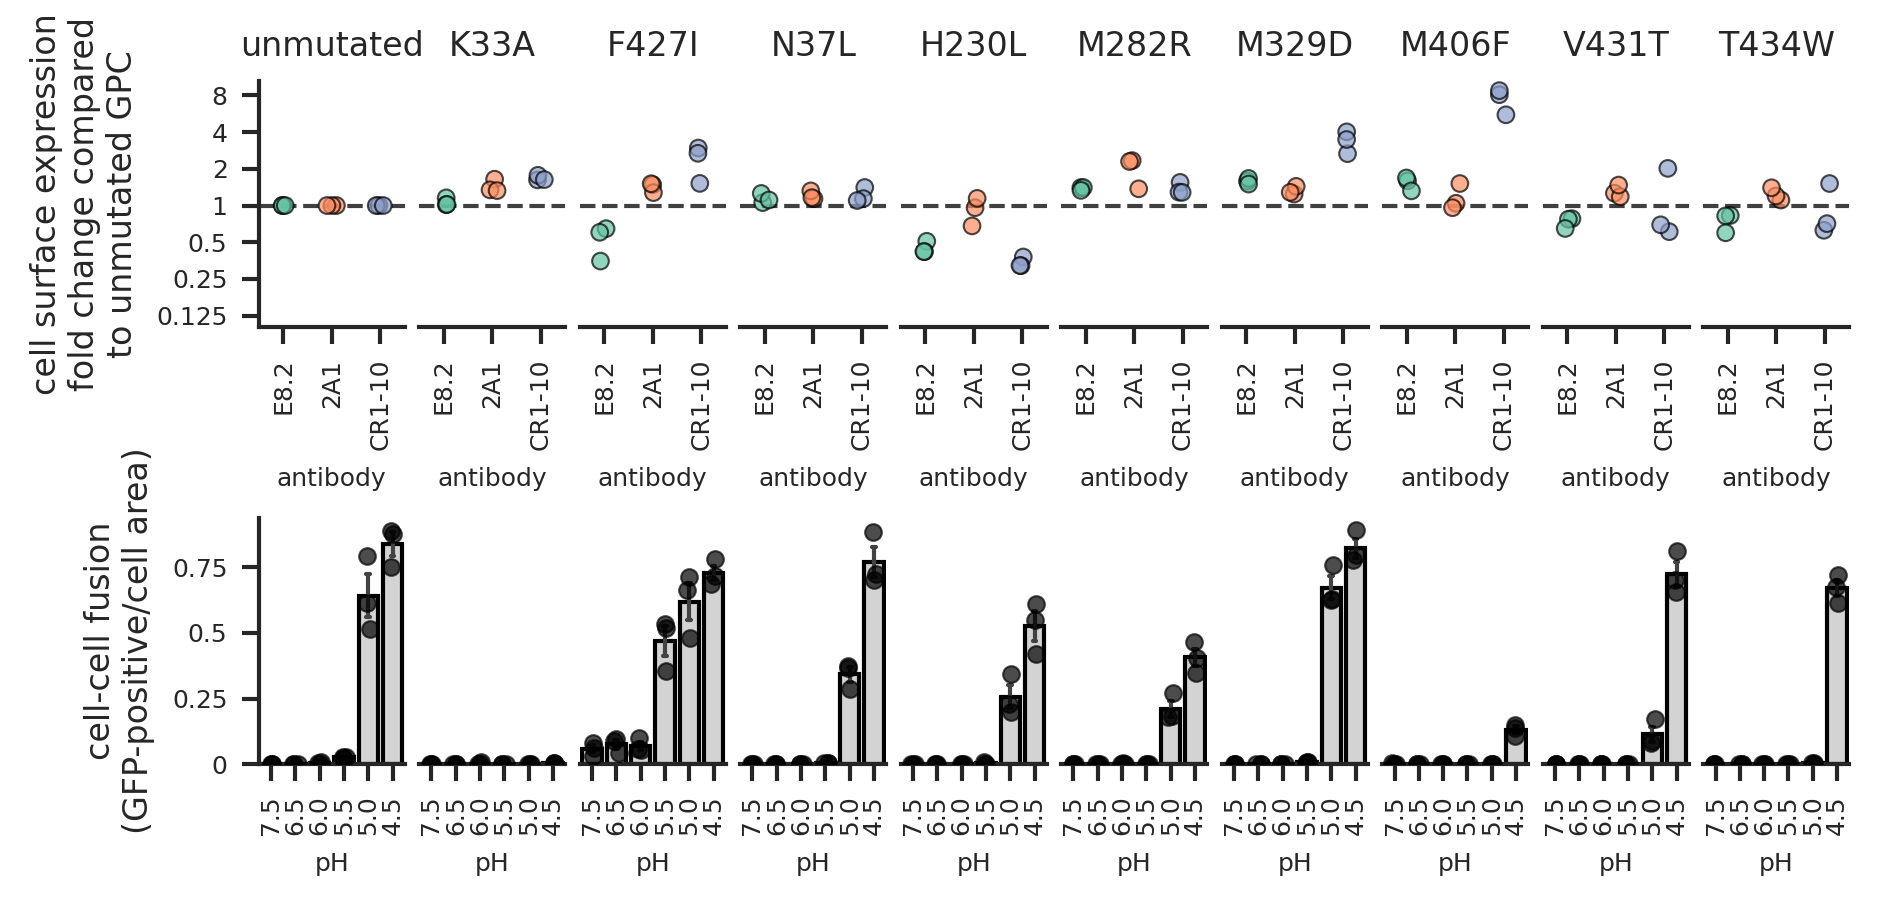

In [4]:
# ---- Settings ----
FUSION_CSV_PATH = "Data/pH_mutants_fusion.csv"      # <-- change to your fusion CSV path
STAINING_CSV_PATH = "Data/pH_mutants_staining.csv"  # <-- change to your staining CSV path

plot_data(FUSION_CSV_PATH, STAINING_CSV_PATH, out_dir, "pH_mutants.svg")

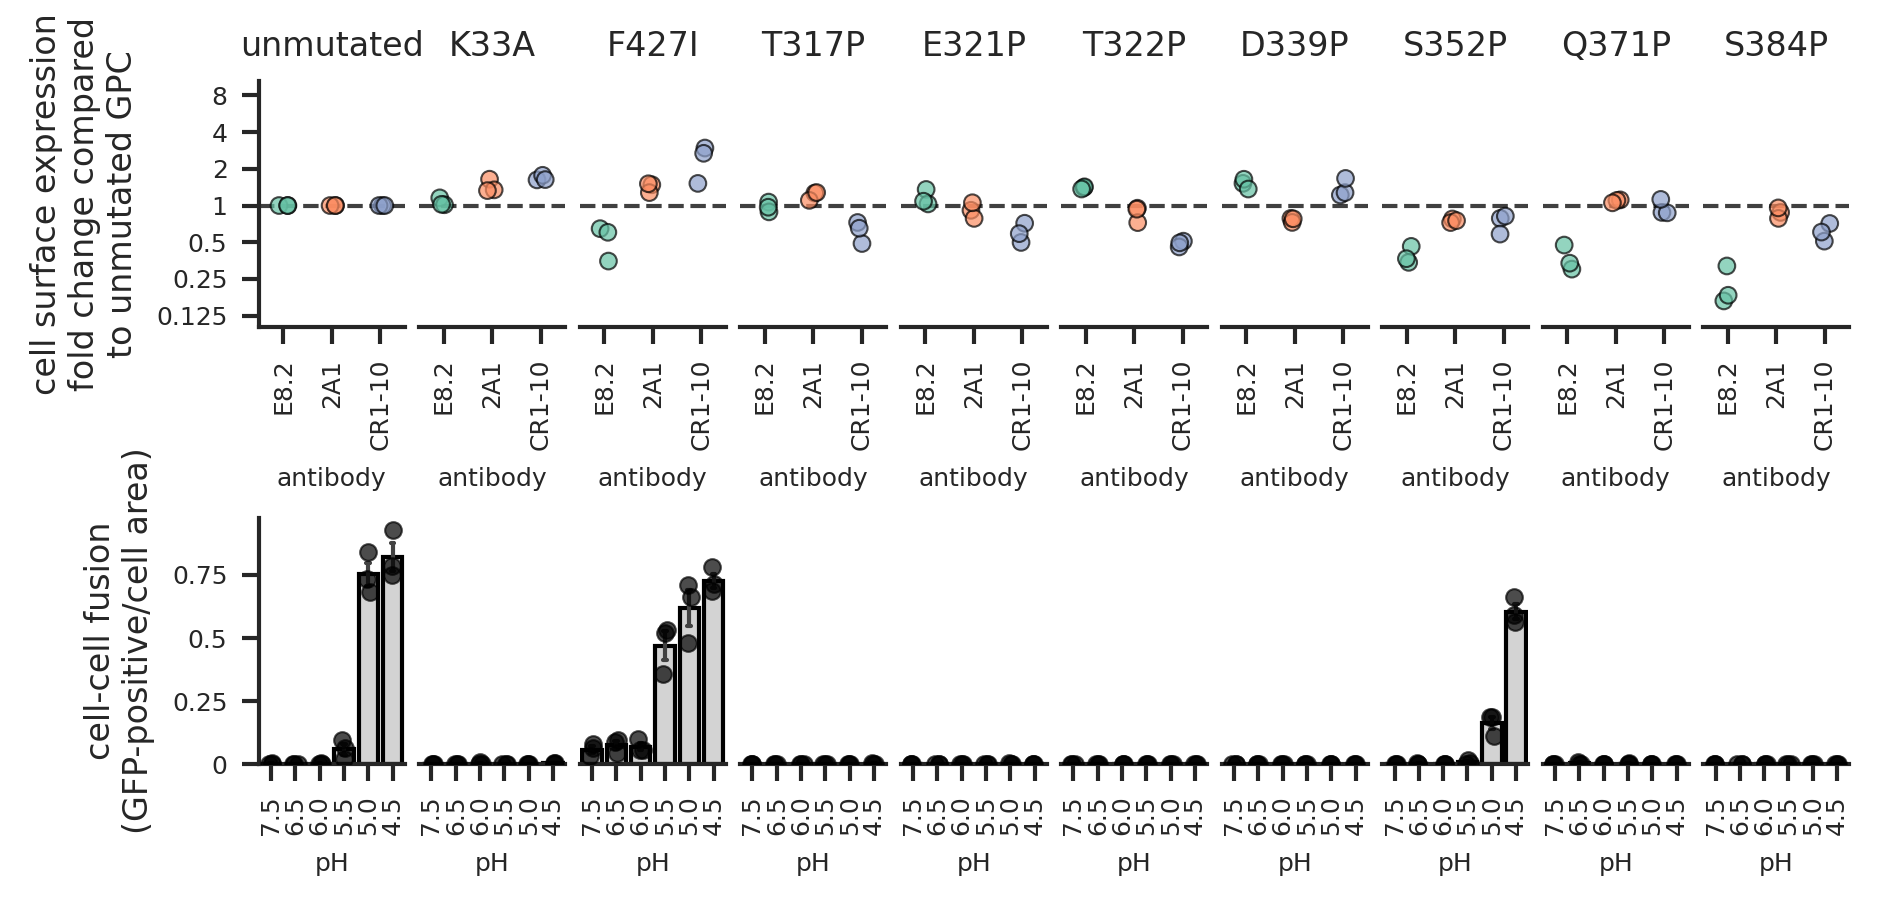

In [5]:
# ---- Settings ----
FUSION_CSV_PATH = "Data/prolines_fusion.csv"      # <-- change to your fusion CSV path
STAINING_CSV_PATH = "Data/prolines_staining.csv"  # <-- change to your staining CSV path

plot_data(FUSION_CSV_PATH, STAINING_CSV_PATH, out_dir, "prolines_mutants.svg")